In [1]:
#Install libraries

%pip install numpy pandas matplotlib seaborn
%pip install opencv-python pillow scikit-learn
%pip install qiskit qiskit-machine-learning
%pip install mlflow joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
#Import libraries

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
#Check dataset

DATA_DIR = Path("data/chest_xray")

for split in ["train", "test", "val"]:
    print(f"\n{split.upper()}")

    for category in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / category

        if folder.exists():
            count = len(list(folder.glob("*")))
            print(category, ":", count)
        else:
            print("Folder not found:", folder)


TRAIN
NORMAL : 1341
PNEUMONIA : 1721

TEST
NORMAL : 234
PNEUMONIA : 390

VAL
NORMAL : 8
PNEUMONIA : 8


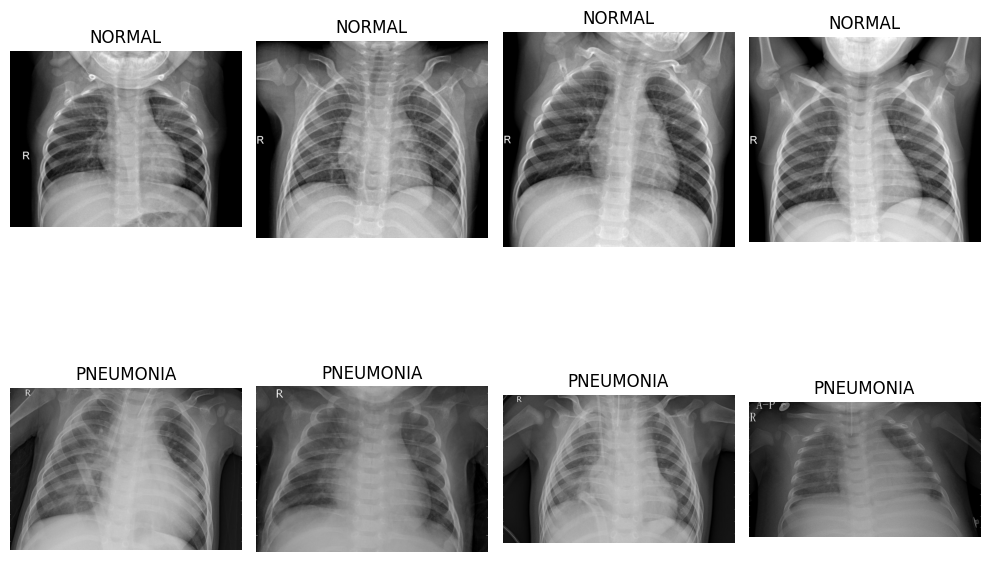

In [4]:
#Display Sample Images

import random
from PIL import Image

categories = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10, 8))

for i, category in enumerate(categories):
    folder = DATA_DIR / "train" / category

    images = list(folder.glob("*"))
    samples = random.sample(images, 4)

    for j, img_path in enumerate(samples):
        img = Image.open(img_path)

        plt.subplot(2, 4, i * 4 + j + 1)
        plt.imshow(img, cmap="gray")
        plt.title(category)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
#Check image dimensions
#Image Information

for category in categories:

    folder = DATA_DIR / "train" / category
    images = list(folder.glob("*"))

    img = Image.open(images[0])

    print("\nCategory:", category)
    print("Image size:", img.size)
    print("Image mode:", img.mode)
    print("Total images:", len(images))


Category: NORMAL
Image size: (2090, 1858)
Image mode: L
Total images: 1341

Category: PNEUMONIA
Image size: (1328, 1368)
Image mode: L
Total images: 1721


Training Dataset Distribution:
{'NORMAL': 1341, 'PNEUMONIA': 1721}


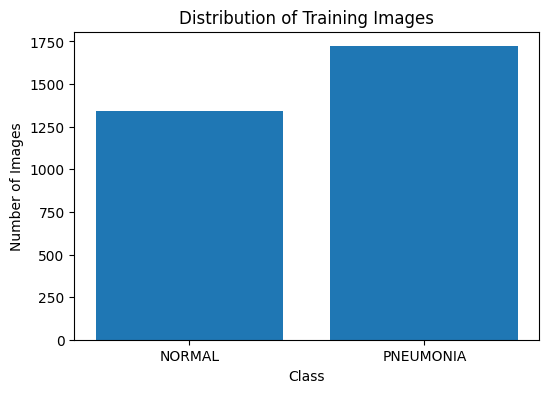

In [6]:
#Check class distribution
#Count images in training and testing folders

train_counts = {}

for category in categories:
    folder = DATA_DIR / "train" / category
    train_counts[category] = len(list(folder.glob("*")))

print("Training Dataset Distribution:")
print(train_counts)

plt.figure(figsize=(6, 4))
plt.bar(train_counts.keys(), train_counts.values())
plt.title("Distribution of Training Images")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [7]:
#Create image preprocessing function

IMG_SIZE = 64

def preprocess_image(image_path):

    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        return None

    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    img = img / 255.0

    return img

Processed image shape: (64, 64)
Minimum pixel value: 0.0
Maximum pixel value: 0.9764705882352941


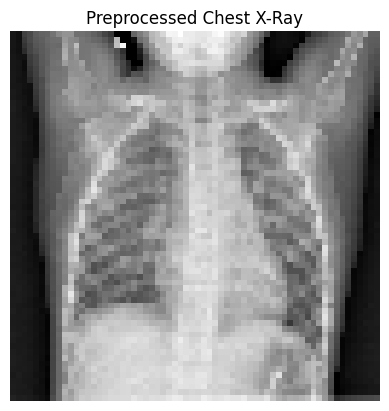

In [8]:
#Test preprocessing on one image

sample_path = list((DATA_DIR / "train" / "NORMAL").glob("*"))[0]

processed_img = preprocess_image(sample_path)

print("Processed image shape:", processed_img.shape)
print("Minimum pixel value:", processed_img.min())
print("Maximum pixel value:", processed_img.max())

plt.imshow(processed_img, cmap="gray")
plt.title("Preprocessed Chest X-Ray")
plt.axis("off")
plt.show()

In [9]:
#Load the Complete Dataset
#Dataset loading function

def load_dataset(split):

    X = []
    y = []

    for category in categories:

        folder = DATA_DIR / split / category

        label = categories.index(category)

        for image_path in folder.glob("*"):

            img = preprocess_image(image_path)

            if img is not None:
                X.append(img)
                y.append(label)

    return np.array(X, dtype=np.float32), np.array(y)


X_train_full, y_train_full = load_dataset("train")

X_test, y_test = load_dataset("test")

print("Training images:", X_train_full.shape)
print("Training labels:", y_train_full.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (3062, 64, 64)
Training labels: (3062,)
Testing images: (624, 64, 64)
Testing labels: (624,)


In [10]:
#Split training data into training and validation sets
#Train-validation split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Final Dataset Shapes")
print("---------------------")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


#Why stratify?
#It maintains approximately the same proportion of NORMAL and PNEUMONIA images in both training and validation sets.

#Why random_state=42?
#It ensures reproducible splitting.

Final Dataset Shapes
---------------------
X_train: (2449, 64, 64)
y_train: (2449,)
X_val: (613, 64, 64)
y_val: (613,)
X_test: (624, 64, 64)
y_test: (624,)


In [11]:
#Verify the datasetv
#Final dataset distribution

print("Training distribution:")
print(pd.Series(y_train).value_counts().rename(index={
    0: "NORMAL",
    1: "PNEUMONIA"
}))

print("\nValidation distribution:")
print(pd.Series(y_val).value_counts().rename(index={
    0: "NORMAL",
    1: "PNEUMONIA"
}))

print("\nTesting distribution:")
print(pd.Series(y_test).value_counts().rename(index={
    0: "NORMAL",
    1: "PNEUMONIA"
}))

Training distribution:
PNEUMONIA    1376
NORMAL       1073
Name: count, dtype: int64

Validation distribution:
PNEUMONIA    345
NORMAL       268
Name: count, dtype: int64

Testing distribution:
PNEUMONIA    390
NORMAL       234
Name: count, dtype: int64


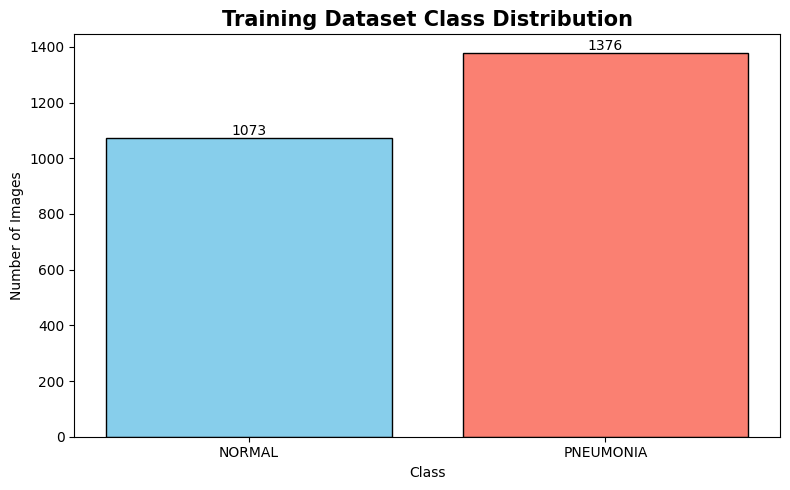

In [12]:
#Exploratory Data Analysis (EDA)
#Class distribution bar chart

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

class_names = ["NORMAL", "PNEUMONIA"]

counts = [
    np.sum(y_train == 0),
    np.sum(y_train == 1)
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_names,
    counts,
    color=["skyblue", "salmon"],
    edgecolor="black"
)

plt.title("Training Dataset Class Distribution",
          fontsize=15, fontweight="bold")
plt.xlabel("Class")
plt.ylabel("Number of Images")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        int(bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()

#What this graph tells us: Whether our dataset contains balanced or imbalanced classes.

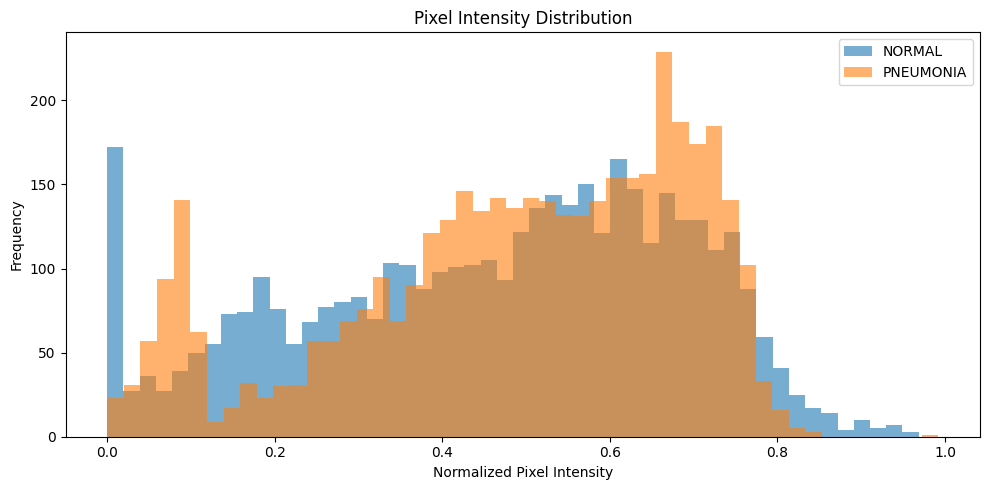

In [13]:
#Pixel intensity distribution

normal_img = X_train[np.where(y_train == 0)[0][0]]
pneumonia_img = X_train[np.where(y_train == 1)[0][0]]

plt.figure(figsize=(10, 5))

plt.hist(
    normal_img.flatten(),
    bins=50,
    alpha=0.6,
    label="NORMAL"
)

plt.hist(
    pneumonia_img.flatten(),
    bins=50,
    alpha=0.6,
    label="PNEUMONIA"
)

plt.title("Pixel Intensity Distribution")
plt.xlabel("Normalized Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.savefig("pixel_intensity.png", dpi=300)
plt.show()

#Viva concept: Pixel intensity represents the brightness value of a pixel. Since we normalized the images, values range from 0 to 1.

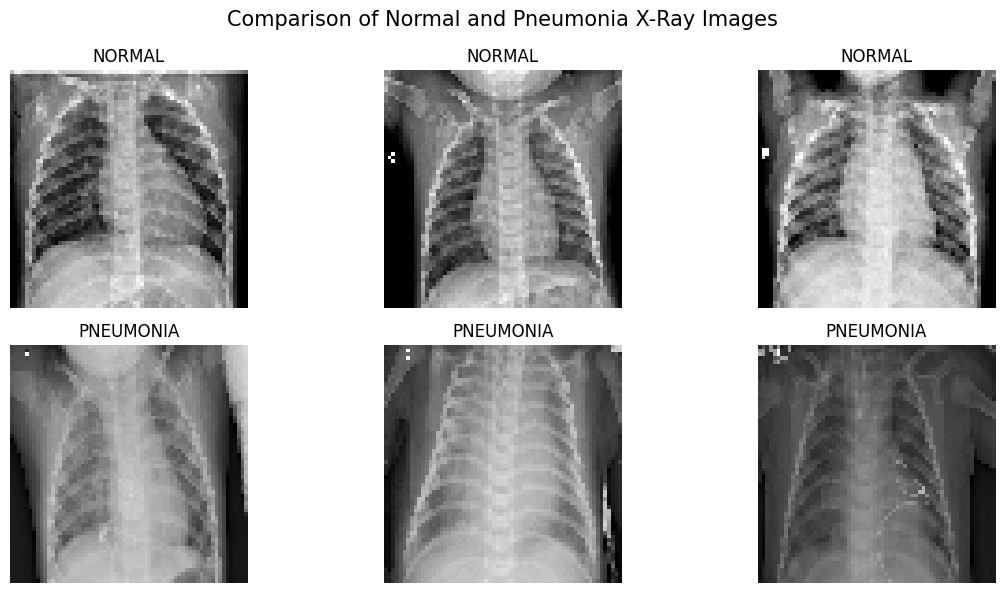

In [14]:
#Compare sample images

plt.figure(figsize=(12, 6))

for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_train[np.where(y_train == 0)[0][i]], cmap="gray")
    plt.title("NORMAL")
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(X_train[np.where(y_train == 1)[0][i]], cmap="gray")
    plt.title("PNEUMONIA")
    plt.axis("off")

plt.suptitle("Comparison of Normal and Pneumonia X-Ray Images",
             fontsize=15)

plt.tight_layout()
plt.savefig("image_comparison.png", dpi=300)
plt.show()

In [15]:
#Feature Extraction using PCA
#Your current images have dimensions:
#64 x 64 = 4096 pixels
#That means each image contains 4,096 numerical pixel features.

#A quantum circuit cannot conveniently process all 4,096 features directly.
#We'll use Principal Component Analysis (PCA) to reduce the feature dimensions.

#6 reduced features

In [16]:
#Flatten images

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("Training shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)
print("Testing shape:", X_test_flat.shape)

Training shape: (2449, 4096)
Validation shape: (613, 4096)
Testing shape: (624, 4096)


In [17]:
#Standardize features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_flat)

X_val_scaled = scaler.transform(X_val_flat)

X_test_scaled = scaler.transform(X_test_flat)

print("Feature scaling completed!")
print("Training shape:", X_train_scaled.shape)

Feature scaling completed!
Training shape: (2449, 4096)


In [18]:
#Apply PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=6, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)

X_val_pca = pca.transform(X_val_scaled)

X_test_pca = pca.transform(X_test_scaled)

print("PCA completed successfully!")

print("Training PCA shape:", X_train_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

#We now have six features for every image.

PCA completed successfully!
Training PCA shape: (2449, 6)
Validation PCA shape: (613, 6)
Testing PCA shape: (624, 6)


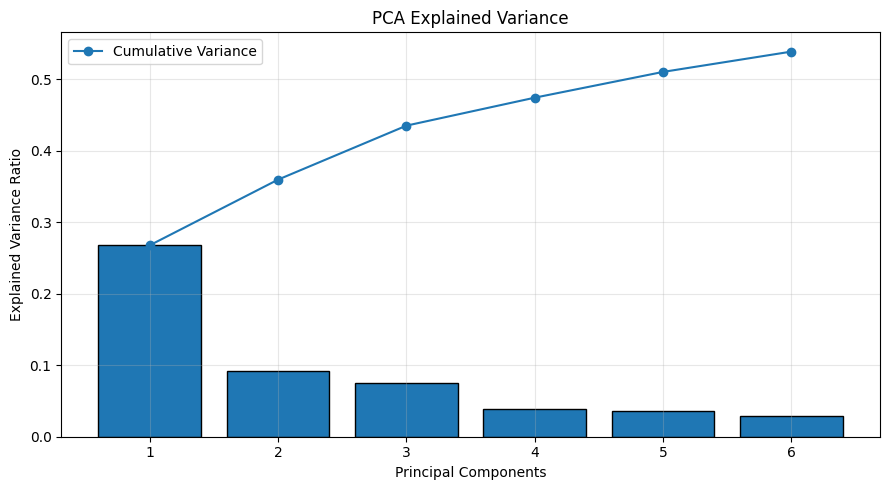

Individual variance: [0.26792443 0.09187084 0.07550223 0.03912142 0.03605374 0.0284154 ]
Total variance: 0.53888804


In [19]:
#PCA explained variance graph

explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, 7),
    explained_variance,
    edgecolor="black"
)

plt.plot(
    range(1, 7),
    np.cumsum(explained_variance),
    marker="o",
    label="Cumulative Variance"
)

plt.title("PCA Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, 7))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("pca_explained_variance.png", dpi=300)
plt.show()

print("Individual variance:", explained_variance)
print("Total variance:", np.sum(explained_variance))

#Explained variance tells us how much of the original data variation is retained by the selected principal components.
#Six components may retain only a small fraction of the original information, so 
#we'll inspect the result rather than assume six components are sufficient for good classification.

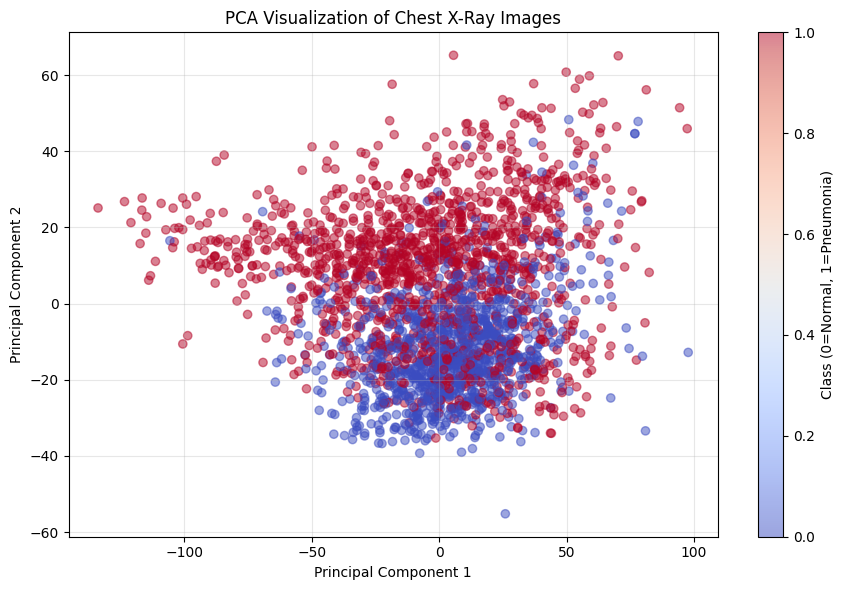

In [20]:
#PCA scatter plot

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Chest X-Ray Images")

plt.colorbar(scatter, label="Class (0=Normal, 1=Pneumonia)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("pca_scatter.png", dpi=300)
plt.show()

#This helps us see whether the two categories form distinguishable groups in the first two principal components.

In [21]:
#Classical Machine Learning Models

#Before implementing quantum ML, we need classical models as baselines.

#We'll train:

#1. Support Vector Machine (SVM).
#2. Random Forest Classifier.

#We'll initially use the same six PCA features for both classical models and QSVC, so the comparison uses the same feature representation.

In [22]:

# Import models

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

# Initialize classical ML models

models = {
    "SVM": SVC(
        kernel="rbf",
        C=1,
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

print("Classical models initialized successfully!")

# Display initialized models
for name, model in models.items():
    print(name, ":", model)


Classical models initialized successfully!
SVM : SVC(C=1, class_weight='balanced', probability=True, random_state=42)
Random Forest : RandomForestClassifier(class_weight='balanced', max_depth=15, n_jobs=-1,
                       random_state=42)


In [23]:
trained_models = {}
results = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train_pca, y_train)

    y_pred = model.predict(X_val_pca)

    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    trained_models[name] = model

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_val,
        y_pred,
        target_names=class_names
    ))


Training: SVM
Accuracy: 0.9005
Precision: 0.9226
Recall: 0.8986
F1 Score: 0.9104

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.87      0.90      0.89       268
   PNEUMONIA       0.92      0.90      0.91       345

    accuracy                           0.90       613
   macro avg       0.90      0.90      0.90       613
weighted avg       0.90      0.90      0.90       613


Training: Random Forest
Accuracy: 0.8874
Precision: 0.8988
Recall: 0.9014
F1 Score: 0.9001

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.87      0.87      0.87       268
   PNEUMONIA       0.90      0.90      0.90       345

    accuracy                           0.89       613
   macro avg       0.89      0.89      0.89       613
weighted avg       0.89      0.89      0.89       613



               Accuracy  Precision    Recall  F1 Score
SVM            0.900489   0.922619  0.898551  0.910426
Random Forest  0.887439   0.898844  0.901449  0.900145


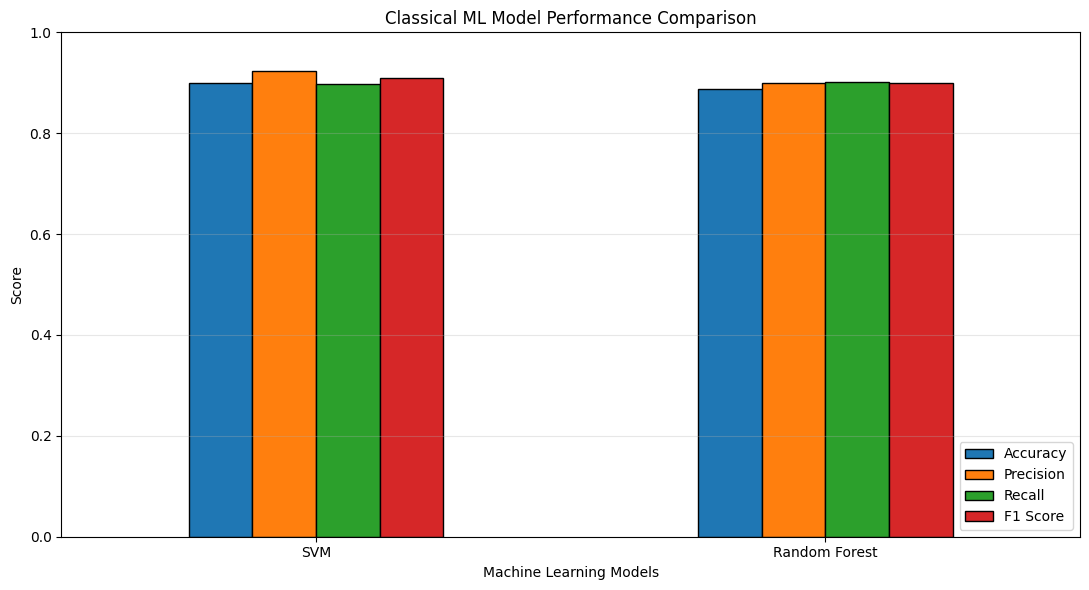

In [24]:
#Model comparison bar chart

results_df = pd.DataFrame(results).T

print(results_df)

results_df.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    edgecolor="black"
)

plt.title("Classical ML Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("classical_model_comparison.png", dpi=300)
plt.show()

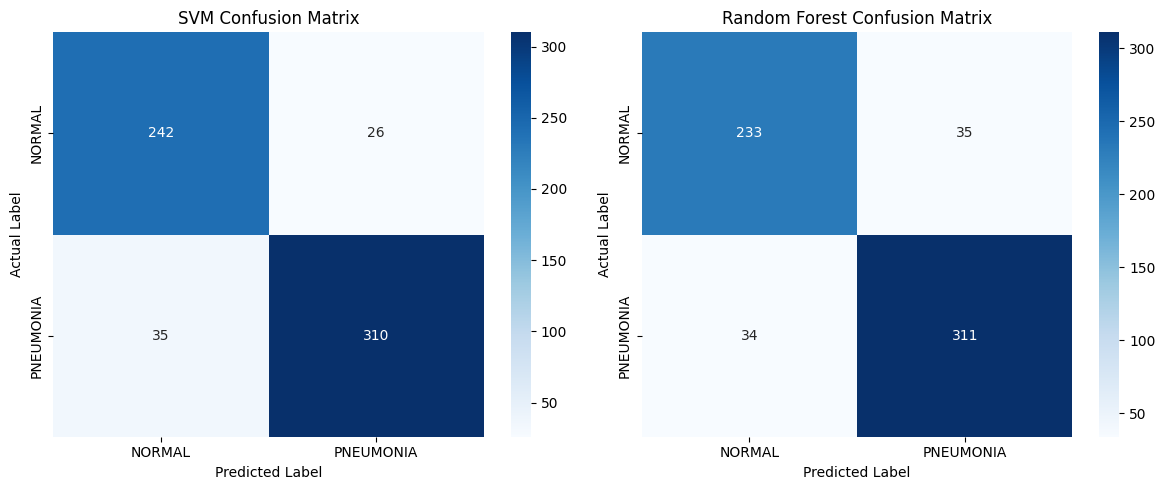

In [25]:
#Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_val_pca)

    cm = confusion_matrix(y_val, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("classical_confusion_matrices.png", dpi=300)
plt.show()

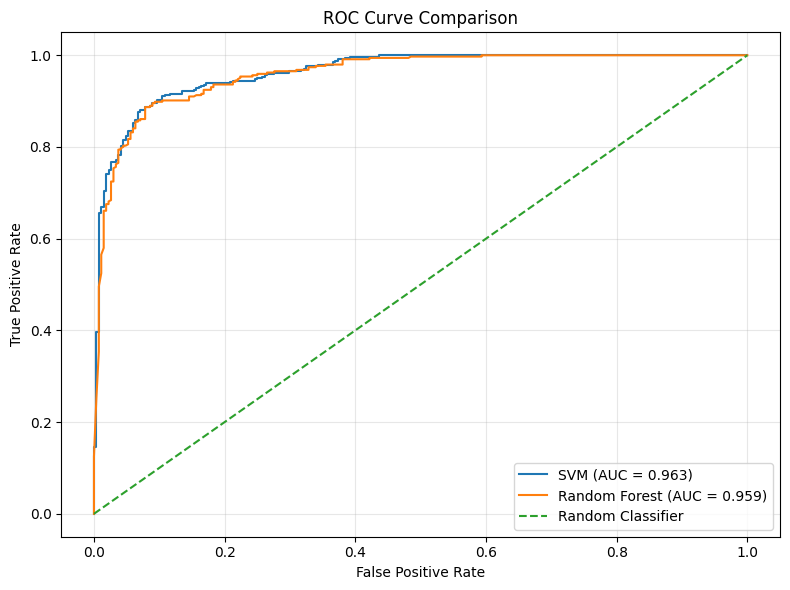

In [26]:
#ROC curves

plt.figure(figsize=(8, 6))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_val_pca)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_val, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("roc_curves.png", dpi=300)
plt.show()

#Why ROC-AUC matters: It measures how well the model distinguishes between the two classes across different classification thresholds.
#For medical-image research, we will pay particular attention to recall for the PNEUMONIA class,
#as missing positive cases is an important limitation to examine.

In [27]:
#Quantum Machine Learning

#We'll use:
#- Qiskit
#- Qiskit Machine Learning
#- Quantum Feature Map
#- Fidelity Quantum Kernel
#- Quantum Support Vector Classifier (QSVC)

#The quantum circuit will encode six PCA features into six qubits.

In [28]:
#Install quantum libraries

%pip install "qiskit>=1.2,<2.0" "qiskit-machine-learning>=0.8,<0.9"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
#Import quantum libraries

from qiskit.circuit.library import ZZFeatureMap
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC

print("Quantum libraries imported successfully!")

Quantum libraries imported successfully!


In [30]:
#Create quantum feature map

num_qubits = 6

feature_map = ZZFeatureMap(
    feature_dimension=num_qubits,
    reps=2,
    entanglement="linear"
)

print("Quantum Feature Map:")
print(feature_map.draw(output="text"))

#Six qubits represent our six input features.
#Hadamard gates help create superposition.
#Rotation operations encode input data.
#Entanglement operations introduce relationships between qubits.
#Two repetitions add more circuit structure.

Quantum Feature Map:
     ┌──────────────────────────────────────────────┐
q_0: ┤0                                             ├
     │                                              │
q_1: ┤1                                             ├
     │                                              │
q_2: ┤2                                             ├
     │  ZZFeatureMap(x[0],x[1],x[2],x[3],x[4],x[5]) │
q_3: ┤3                                             ├
     │                                              │
q_4: ┤4                                             ├
     │                                              │
q_5: ┤5                                             ├
     └──────────────────────────────────────────────┘


In [31]:
#Create quantum kernel

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map
)

print("Quantum Kernel created successfully!")

Quantum Kernel created successfully!


In [32]:
#Prepare a smaller quantum dataset
#We'll start with 80 training images and 40 validation images, balanced between the two classes

from sklearn.model_selection import train_test_split

X_quantum_train, _, y_quantum_train, _ = train_test_split(
    X_train_pca,
    y_train,
    train_size=80,
    random_state=42,
    stratify=y_train
)

X_quantum_val, _, y_quantum_val, _ = train_test_split(
    X_val_pca,
    y_val,
    train_size=40,
    random_state=42,
    stratify=y_val
)

print("Quantum training shape:", X_quantum_train.shape)
print("Quantum validation shape:", X_quantum_val.shape)

#The smaller quantum sample is a computational compromise, not evidence that QSVC has been evaluated on the entire dataset.

Quantum training shape: (80, 6)
Quantum validation shape: (40, 6)


In [33]:
#Train Quantum SVC

qsvc = QSVC(
    quantum_kernel=quantum_kernel
)

print("Training Quantum SVC...")

qsvc.fit(
    X_quantum_train,
    y_quantum_train
)

print("Quantum SVC training completed!")

Training Quantum SVC...
Quantum SVC training completed!


In [34]:
#Quantum predictions

y_quantum_pred = qsvc.predict(X_quantum_val)

quantum_accuracy = accuracy_score(
    y_quantum_val,
    y_quantum_pred
)

quantum_precision = precision_score(
    y_quantum_val,
    y_quantum_pred
)

quantum_recall = recall_score(
    y_quantum_val,
    y_quantum_pred
)

quantum_f1 = f1_score(
    y_quantum_val,
    y_quantum_pred
)

print("Quantum Model Results")
print("----------------------")
print("Accuracy:", quantum_accuracy)
print("Precision:", quantum_precision)
print("Recall:", quantum_recall)
print("F1 Score:", quantum_f1)

print("\nClassification Report:")
print(classification_report(
    y_quantum_val,
    y_quantum_pred,
    target_names=class_names
))

Quantum Model Results
----------------------
Accuracy: 0.55
Precision: 0.5757575757575758
Recall: 0.8260869565217391
F1 Score: 0.6785714285714286

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.43      0.18      0.25        17
   PNEUMONIA       0.58      0.83      0.68        23

    accuracy                           0.55        40
   macro avg       0.50      0.50      0.46        40
weighted avg       0.51      0.55      0.50        40



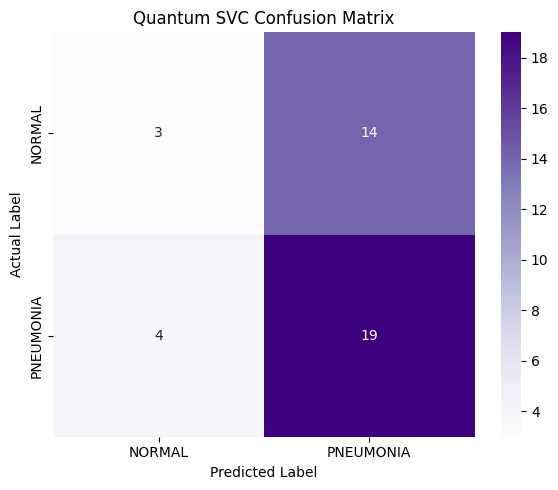

In [35]:
#Quantum confusion matrix

plt.figure(figsize=(6, 5))

cm = confusion_matrix(
    y_quantum_val,
    y_quantum_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Quantum SVC Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.savefig("quantum_confusion_matrix.png", dpi=300)
plt.show()

In [36]:
#Final model comparison
#We need to compare all three models using the same 40 validation images for a fair comparison.

comparison = {}

for name, model in trained_models.items():

    predictions = model.predict(X_quantum_val)

    comparison[name] = {
        "Accuracy": accuracy_score(y_quantum_val, predictions),
        "Precision": precision_score(y_quantum_val, predictions),
        "Recall": recall_score(y_quantum_val, predictions),
        "F1 Score": f1_score(y_quantum_val, predictions)
    }

comparison["Quantum SVC"] = {
    "Accuracy": accuracy_score(y_quantum_val, y_quantum_pred),
    "Precision": precision_score(y_quantum_val, y_quantum_pred),
    "Recall": recall_score(y_quantum_val, y_quantum_pred),
    "F1 Score": f1_score(y_quantum_val, y_quantum_pred)
}

comparison_df = pd.DataFrame(comparison).T

print(comparison_df.round(4))

               Accuracy  Precision  Recall  F1 Score
SVM               0.875     0.9091  0.8696    0.8889
Random Forest     0.875     0.9091  0.8696    0.8889
Quantum SVC       0.550     0.5758  0.8261    0.6786


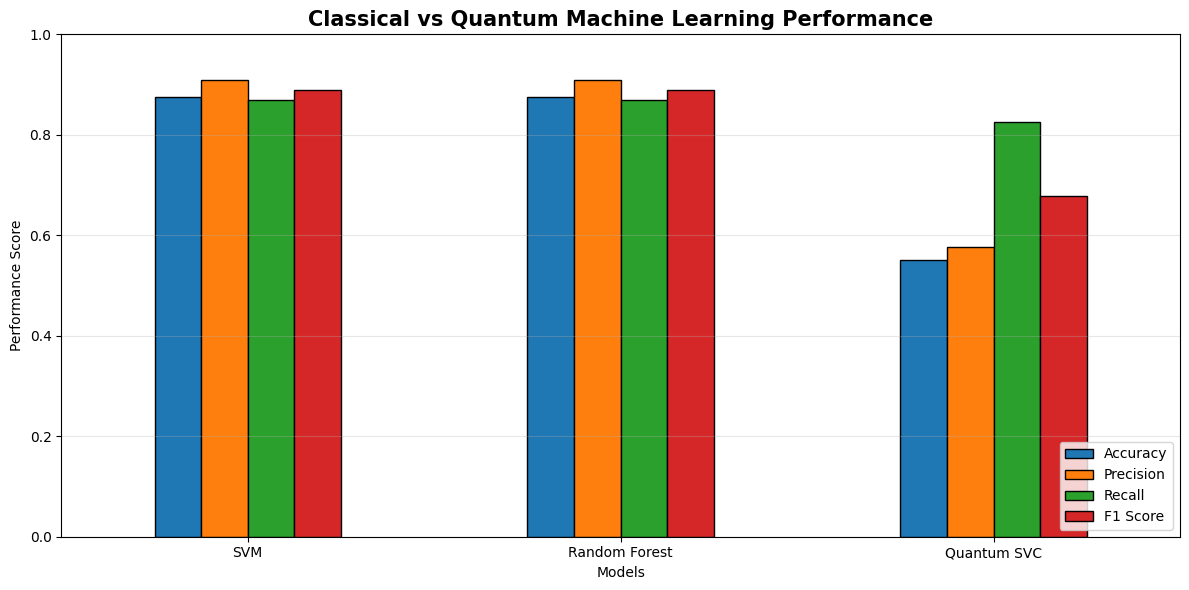

In [37]:
#Final comparison graph

ax = comparison_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    edgecolor="black"
)

plt.title(
    "Classical vs Quantum Machine Learning Performance",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("final_model_comparison.png", dpi=300)
plt.show()

In [38]:
#Find the best validation model

best_model_name = comparison_df["F1 Score"].idxmax()

print("Best model based on validation F1-score:", best_model_name)

print("\nPerformance:")
print(comparison_df.loc[best_model_name])

Best model based on validation F1-score: SVM

Performance:
Accuracy     0.875000
Precision    0.909091
Recall       0.869565
F1 Score     0.888889
Name: SVM, dtype: float64


In [39]:
#MLflow Experiment Tracking

#MLflow is a tool used to track machine learning experiments.

#MLflow records:
#- Algorithm name.
#- Hyperparameters.
#- Accuracy.
#- Precision.
#- Recall.
#- F1-score.
#- Experiment history.

In [40]:
#Install MLflow

%pip install mlflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
#Import MLflow

import mlflow
import mlflow.sklearn
import joblib
import os

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("MLflow imported successfully!")

MLflow imported successfully!


In [42]:
#Configure MLflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")

mlflow.set_experiment(
    "Quantum_ML_Pneumonia_Classification"
)

print("MLflow experiment configured successfully!")

MLflow experiment configured successfully!


In [43]:
#Run three experiments
#We'll train three different configurations using the full training PCA features and evaluate them on the full validation set.

experiment_models = {
    "SVM_C1": SVC(
        kernel="rbf",
        C=1,
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "SVM_C10": SVC(
        kernel="rbf",
        C=10,
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "Random_Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

mlflow_results = []

for name, model in experiment_models.items():

    with mlflow.start_run(run_name=name):

        model.fit(X_train_pca, y_train)

        predictions = model.predict(X_val_pca)

        accuracy = accuracy_score(y_val, predictions)
        precision = precision_score(y_val, predictions)
        recall = recall_score(y_val, predictions)
        f1 = f1_score(y_val, predictions)

        mlflow.log_param("algorithm", name)
        mlflow.log_param("pca_components", 6)

        if name.startswith("SVM"):
            mlflow.log_param("kernel", "rbf")
            mlflow.log_param("C", model.C)

        else:
            mlflow.log_param("n_estimators", 100)
            mlflow.log_param("max_depth", 15)

        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1_score", f1)

        
        mlflow.sklearn.log_model(
        model,
        name="model",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
        )


        mlflow_results.append({
            "Run": name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

        print(name, "completed!")

SVM_C1 completed!
SVM_C10 completed!
Random_Forest completed!


             Run  Accuracy  Precision  Recall  F1 Score
0         SVM_C1    0.9005     0.9226  0.8986    0.9104
1        SVM_C10    0.8923     0.9240  0.8812    0.9021
2  Random_Forest    0.8874     0.8988  0.9014    0.9001


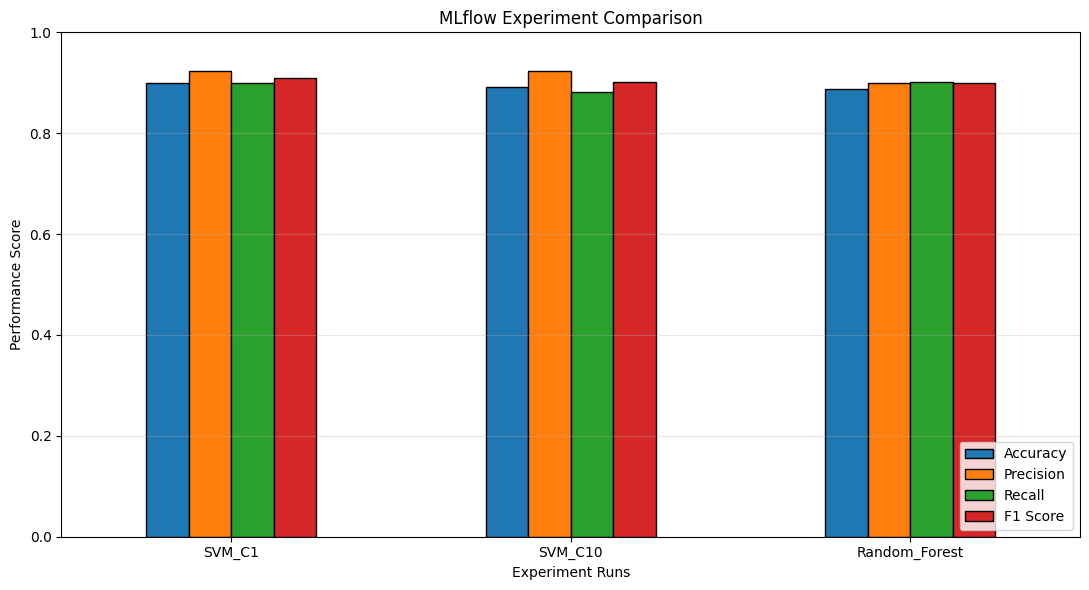

In [44]:
#Display MLflow results

mlflow_df = pd.DataFrame(mlflow_results)

print(mlflow_df.round(4))

mlflow_df.set_index("Run").plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    edgecolor="black"
)

plt.title("MLflow Experiment Comparison")
plt.xlabel("Experiment Runs")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig("mlflow_comparison.png", dpi=300)
plt.show()

In [45]:
# Select the best model based on F1 Score

best_model_name = mlflow_df.loc[
    mlflow_df["F1 Score"].idxmax(), "Run"
]

best_model = experiment_models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:",
      mlflow_df["F1 Score"].max())

Best Model: SVM_C1
Best F1 Score: 0.9104258443465492


In [46]:
import os
import joblib

# Create model directory
os.makedirs("model", exist_ok=True)

# Save the complete preprocessing and model pipeline
model_bundle = {
    "model": best_model,
    "scaler": scaler,
    "pca": pca,
    "image_size": IMG_SIZE,
    "class_names": ["NORMAL", "PNEUMONIA"]
}

joblib.dump(
    model_bundle,
    "model/best_model_pipeline.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!


In [47]:
# Load the saved model

loaded_bundle = joblib.load(
    "model/best_model_pipeline.joblib"
)

print("Model loaded successfully!")
print("Model:", type(loaded_bundle["model"]).__name__)
print("Image Size:", loaded_bundle["image_size"])
print("Classes:", loaded_bundle["class_names"])

Model loaded successfully!
Model: SVC
Image Size: 64
Classes: ['NORMAL', 'PNEUMONIA']


In [48]:
#Calculate final test metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict on official test dataset
y_test_pred = best_model.predict(X_test_pca)

# Calculate performance metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)

print("FINAL TEST RESULTS")
print("------------------")
print("Accuracy:", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1 Score:", round(test_f1, 4))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))


FINAL TEST RESULTS
------------------
Accuracy: 0.8397
Precision: 0.8856
Recall: 0.8538
F1 Score: 0.8695

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.77      0.82      0.79       234
   PNEUMONIA       0.89      0.85      0.87       390

    accuracy                           0.84       624
   macro avg       0.83      0.84      0.83       624
weighted avg       0.84      0.84      0.84       624



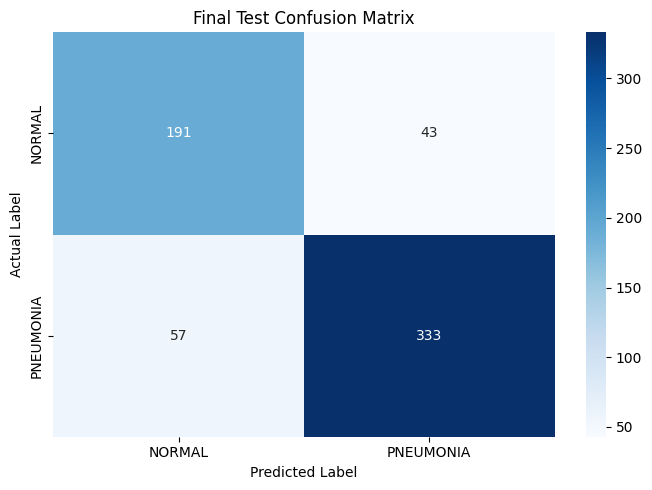

In [49]:
#Generate confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig("final_test_confusion_matrix.png", dpi=300)
plt.show()

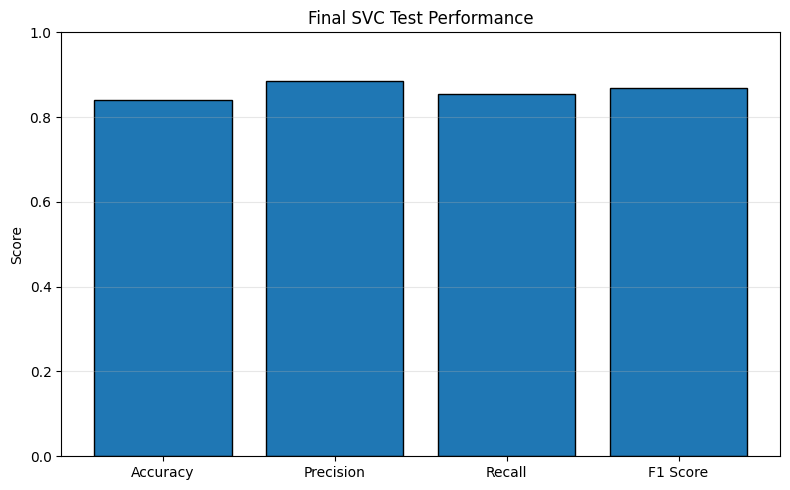

In [50]:
#Plot final performance metrics

metrics = {
    "Accuracy": test_accuracy,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1 Score": test_f1
}

plt.figure(figsize=(8, 5))

plt.bar(
    metrics.keys(),
    metrics.values(),
    edgecolor="black"
)

plt.ylim(0, 1)
plt.title("Final SVC Test Performance")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("final_test_metrics.png", dpi=300)
plt.show()

In [51]:
#Save final results

import pandas as pd

final_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

final_results.to_csv(
    "final_test_results.csv",
    index=False
)

print(final_results.round(4))
print("\nFinal test results saved successfully!")

      Metric   Score
0   Accuracy  0.8397
1  Precision  0.8856
2     Recall  0.8538
3   F1 Score  0.8695

Final test results saved successfully!
